In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [3]:
# Display / plotting configuration
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 120)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (9, 5)
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'

RAW_PATH = 'bank_for_students.csv'   # <-- update path if needed
print("Libraries loaded successfully.")


Libraries loaded successfully.


### SPRINT 1 - DATA UNDERSTANDING & PREPARATION

1. Understand the banking business problem and identify:
- Business objective
- Business problem
- Expected outcome
- Importance of customer response analysis
- Possible decisions supported by the analysis
- Understand what the bank is trying to achieve through its marketing campaigns.


## 2. Dataset Understanding

In [5]:
df_raw = pd.read_csv('Bank_Students.csv')
print("Shape:", df_raw.shape)
df_raw.head()

Shape: (11162, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59.0,admin.,married,secondary,no,2343.0,yes,no,unknown,5,may,1042.0,1,-1,0,unknown,yes
1,56.0,admin.,married,secondary,no,45.0,no,no,unknown,5,may,1467.0,1,-1,0,unknown,yes
2,41.0,technician,married,secondary,no,1270.0,yes,no,unknown,5,may,1389.0,1,-1,0,unknown,yes
3,55.0,services,married,secondary,no,2476.0,yes,no,unknown,5,may,579.0,1,-1,0,unknown,yes
4,54.0,admin.,married,tertiary,no,184.0,no,no,unknown,5,may,673.0,2,-1,0,unknown,yes


In [6]:
print("Number of rows:", df_raw.shape[0])
print("Number of columns:", df_raw.shape[1])
print()
df_raw.info()

Number of rows: 11162
Number of columns: 17

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11162 entries, 0 to 11161
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        11042 non-null  object
 1   job        11062 non-null  object
 2   marital    11162 non-null  object
 3   education  11062 non-null  object
 4   default    11162 non-null  object
 5   balance    11042 non-null  object
 6   housing    11162 non-null  object
 7   loan       11162 non-null  object
 8   contact    11062 non-null  object
 9   day        11162 non-null  int64 
 10  month      11162 non-null  object
 11  duration   11043 non-null  object
 12  campaign   11162 non-null  int64 
 13  pdays      11162 non-null  int64 
 14  previous   11162 non-null  int64 
 15  poutcome   11062 non-null  object
 16  deposit    11162 non-null  object
dtypes: int64(4), object(13)
memory usage: 1.4+ MB


## 3. DataFrame Exploration

In [9]:
df_raw.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,11042,87,31.0,491,NaN,NaN,NaN,NaN,NaN,NaN,NaN
job,11062,12,management,2544,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital,11162,3,married,6351,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,11062,4,secondary,5431,NaN,NaN,NaN,NaN,NaN,NaN,NaN
default,11162,2,no,10994,NaN,NaN,NaN,NaN,NaN,NaN,NaN
balance,11042,3789,0.0,766,NaN,NaN,NaN,NaN,NaN,NaN,NaN
housing,11162,2,no,5881,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,11162,2,no,9702,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,11062,3,cellular,7971,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day,11162.0,NaN,NaN,NaN,15.658036,8.42074,1.0,8.0,15.0,22.0,31.0


In [10]:
df_raw.dtypes


age          object
job          object
marital      object
education    object
default      object
balance      object
housing      object
loan         object
contact      object
day           int64
month        object
duration     object
campaign      int64
pdays         int64
previous      int64
poutcome     object
deposit      object
dtype: object

In [11]:
# Missing value
missing = df_raw.isnull().sum()
missing_pct = (missing / len(df_raw) * 100).round(2)
pd.DataFrame({'missing_count': missing, 'missing_pct': missing_pct}).sort_values('missing_count', ascending=False)

,missing_count,missing_pct
age,120,1.08
balance,120,1.08
duration,119,1.07
poutcome,100,0.90
job,100,0.90
contact,100,0.90
education,100,0.90
housing,0,0.00
loan,0,0.00
default,0,0.00


In [12]:
for col in df_raw.columns:
    print(f"{col:12s} -> {df_raw[col].nunique(dropna=True)} unique values")


age          -> 87 unique values
job          -> 12 unique values
marital      -> 3 unique values
education    -> 4 unique values
default      -> 2 unique values
balance      -> 3789 unique values
housing      -> 2 unique values
loan         -> 2 unique values
contact      -> 3 unique values
day          -> 31 unique values
month        -> 12 unique values
duration     -> 1435 unique values
campaign     -> 46 unique values
pdays        -> 472 unique values
previous     -> 34 unique values
poutcome     -> 4 unique values
deposit      -> 2 unique values


In [14]:
# Frequency tables for the categorical-looking columns
value_counts = ['job','marital','education','default','housing','loan','contact','month','poutcome','deposit']
for col in cat_like_cols:
    print(f"--- {col} ---")
    print(df_raw[col].value_counts(dropna=False))
    print()

--- job ---
job
management       2544
blue-collar      1921
technician       1803
admin.           1326
services          917
retired           771
self-employed     401
unemployed        357
student           356
entrepreneur      322
housemaid         274
NaN               100
unknown            70
Name: count, dtype: int64

--- marital ---
marital
married     6351
single      3518
divorced    1293
Name: count, dtype: int64

--- education ---
education
secondary    5431
tertiary     3651
primary      1488
unknown       492
NaN           100
Name: count, dtype: int64

--- default ---
default
no     10994
yes      168
Name: count, dtype: int64

--- housing ---
housing
no     5881
yes    5281
Name: count, dtype: int64

--- loan ---
loan
no     9702
yes    1460
Name: count, dtype: int64

--- contact ---
contact
cellular     7971
unknown      2323
telephone     768
NaN           100
Name: count, dtype: int64

--- month ---
month
may    2824
aug    1519
jul    1514
jun    1222
nov     943


## 4. Data Cleaning

In [21]:
df = df_raw.copy()
cleaning_log = []

for col in ['age', 'balance', 'duration']:
    df[col] = pd.to_numeric(df[col], errors='coerce')
    cleaning_log.append({
        'Problem': f'{col} contains non-numeric values',
        'Action': 'Converted to numeric; invalid values → NaN'
    })
pd.to_numeric(df[col], errors='coerce')

0        1042.0
1        1467.0
2        1389.0
3         579.0
4         673.0
          ...  
11157     257.0
11158      83.0
11159     156.0
11160       9.0
11161     628.0
Name: duration, Length: 11162, dtype: float64

In [22]:
# --- 4.2 Missing values overview after numeric conversion --------------------------------
print("Missing values after numeric conversion:")
print(df.isnull().sum()[df.isnull().sum() > 0])


Missing values after numeric conversion:
age          125
job          100
education    100
balance      125
contact      100
duration     124
poutcome     100
dtype: int64


In [24]:
for col in ['job', 'education', 'contact', 'poutcome']:
    df[col] = df[col].fillna('unknown')
df

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59.0,admin.,married,secondary,no,2343.0,yes,no,unknown,5,may,1042.0,1,-1,0,unknown,yes
1,56.0,admin.,married,secondary,no,45.0,no,no,unknown,5,may,1467.0,1,-1,0,unknown,yes
2,41.0,technician,married,secondary,no,1270.0,yes,no,unknown,5,may,1389.0,1,-1,0,unknown,yes
3,55.0,services,married,secondary,no,2476.0,yes,no,unknown,5,may,579.0,1,-1,0,unknown,yes
4,54.0,admin.,married,tertiary,no,184.0,no,no,unknown,5,may,673.0,2,-1,0,unknown,yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11157,33.0,blue-collar,single,primary,no,1.0,yes,no,cellular,20,apr,257.0,1,-1,0,unknown,no
11158,39.0,services,married,secondary,no,733.0,no,no,unknown,16,jun,83.0,4,-1,0,unknown,no
11159,32.0,technician,single,secondary,no,29.0,no,no,cellular,19,aug,156.0,2,-1,0,unknown,no
11160,43.0,technician,married,secondary,no,0.0,no,yes,cellular,8,may,9.0,2,172,5,failure,no


In [25]:
print("Remaining nulls:\n", df[['age','balance','duration']].isnull().sum())

# age: small number of missing (~125) -> impute with median (robust to skew), age is customer-level
df['age'] = df['age'].fillna(df['age'].median())

# balance: impute with median (balance is heavily skewed by high earners; mean would be distorted)
df['balance'] = df['balance'].fillna(df['balance'].median())

# duration: impute with median (right-skewed call-duration distribution)
df['duration'] = df['duration'].fillna(df['duration'].median())


Remaining nulls:
 age         125
balance     125
duration    124
dtype: int64


In [26]:
n_dupes = df.duplicated().sum()
print("Fully duplicated rows:", n_dupes)

if n_dupes > 0:
    df = df.drop_duplicates()


Fully duplicated rows: 0


In [27]:
print("Age range before cleaning:", df['age'].min(), '-', df['age'].max())
implausible_age = df[(df['age'] < 18) | (df['age'] > 100)]
print("Implausible ages (<18 or >100):", len(implausible_age))
print(sorted(implausible_age['age'].unique()))


Age range before cleaning: 18.0 - 146.0
Implausible ages (<18 or >100): 12
[np.float64(122.0), np.float64(123.0), np.float64(124.0), np.float64(127.0), np.float64(134.0), np.float64(137.0), np.float64(138.0), np.float64(139.0), np.float64(141.0), np.float64(146.0)]


In [29]:
before = len(df)
df = df[(df['age'] >= 18) & (df['age'] <= 100)]
after = len(df)
print(f"Rows removed: {before-after}. New shape: {df.shape}")

Rows removed: 0. New shape: (11150, 17)


In [30]:
# 4.7 pdays sentinel value -1 
print("pdays = -1 count:", (df['pdays'] == -1).sum(), f"({(df['pdays']==-1).mean()*100:.1f}% of customers)")
print(df['pdays'].describe())


pdays = -1 count: 8316 (74.6% of customers)
count    11150.000000
mean        51.279372
std        108.659050
min         -1.000000
25%         -1.000000
50%         -1.000000
75%         19.250000
max        854.000000
Name: pdays, dtype: float64


## 5. Outlier Analysis

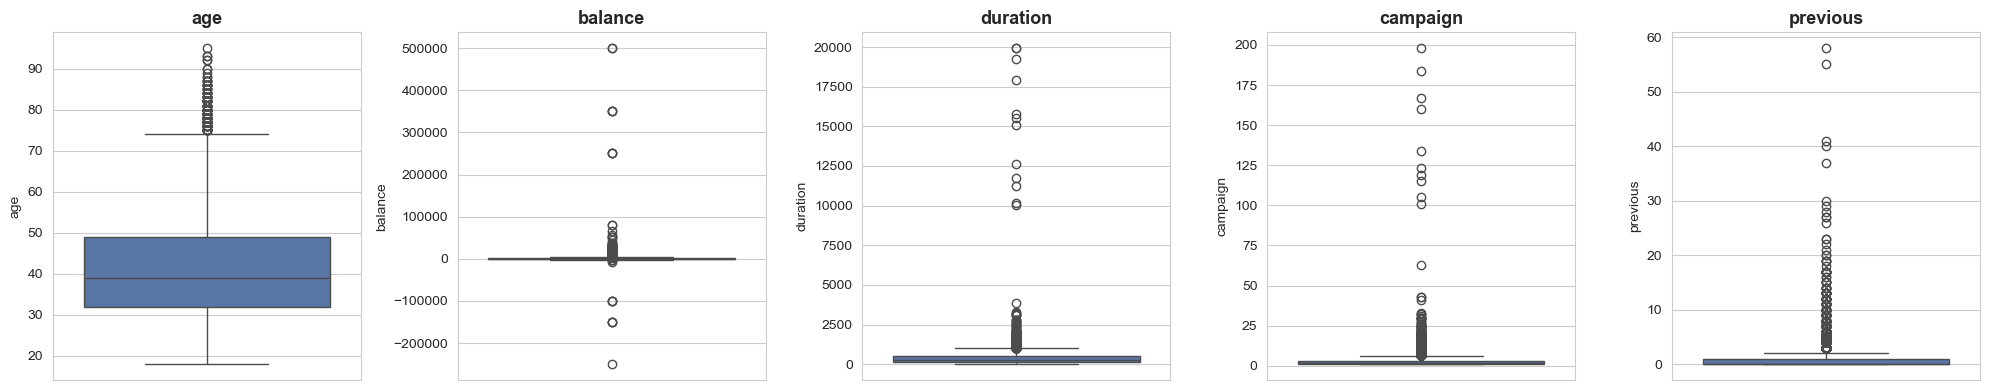

In [31]:
num_cols_outlier_check = ['age', 'balance', 'duration', 'campaign', 'previous']

fig, axes = plt.subplots(1, len(num_cols_outlier_check), figsize=(20, 4))
for ax, col in zip(axes, num_cols_outlier_check):
    sns.boxplot(y=df[col], ax=ax, color='#4C72B0')
    ax.set_title(col)
plt.tight_layout()
plt.show()


In [32]:
def iqr_bounds(series, k=1.5):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k*iqr, q3 + k*iqr

for col in num_cols_outlier_check:
    low, high = iqr_bounds(df[col])
    n_out = ((df[col] < low) | (df[col] > high)).sum()
    print(f"{col:10s} IQR bounds: [{low:,.1f}, {high:,.1f}]  -> {n_out} potential outliers "
          f"({n_out/len(df)*100:.1f}%)")


age        IQR bounds: [6.5, 74.5]  -> 167 potential outliers (1.5%)
balance    IQR bounds: [-2,226.0, 4,046.0]  -> 1070 potential outliers (9.6%)
duration   IQR bounds: [-390.5, 1,021.5]  -> 661 potential outliers (5.9%)
campaign   IQR bounds: [-2.0, 6.0]  -> 609 potential outliers (5.5%)
previous   IQR bounds: [-1.5, 2.5]  -> 1255 potential outliers (11.3%)


## 6. Categorical Data Validation

In [33]:
cat_cols = ['job','marital','education','default','housing','loan','contact','month','poutcome','deposit']
for col in cat_cols:
    print(f"{col:10s}: {sorted(df[col].astype(str).unique())}")


job       : ['admin.', 'blue-collar', 'entrepreneur', 'housemaid', 'management', 'retired', 'self-employed', 'services', 'student', 'technician', 'unemployed', 'unknown']
marital   : ['divorced', 'married', 'single']
education : ['primary', 'secondary', 'tertiary', 'unknown']
default   : ['no', 'yes']
housing   : ['no', 'yes']
loan      : ['no', 'yes']
contact   : ['cellular', 'telephone', 'unknown']
month     : ['apr', 'aug', 'dec', 'feb', 'jan', 'jul', 'jun', 'mar', 'may', 'nov', 'oct', 'sep']
poutcome  : ['failure', 'other', 'success', 'unknown']
deposit   : ['no', 'yes']


## 7. Target Variable Validation

deposit
no     5867
yes    5283
Name: count, dtype: int64
deposit
no     52.62
yes    47.38
Name: proportion, dtype: float64


C:\Users\saket\AppData\Local\Temp\ipykernel_23824\3692333882.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x='deposit', data=df, palette=['#C44E52','#55A868'], order=['no','yes'])


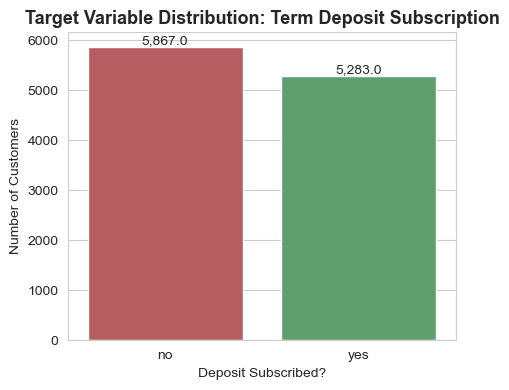

In [35]:
target_counts = df['deposit'].value_counts()
target_pct = df['deposit'].value_counts(normalize=True)*100
print(target_counts)
print(target_pct.round(2))

plt.figure(figsize=(5,4))
ax = sns.countplot(x='deposit', data=df, palette=['#C44E52','#55A868'], order=['no','yes'])
for p in ax.patches:
    ax.annotate(f'{p.get_height():,}', (p.get_x()+p.get_width()/2, p.get_height()),
                ha='center', va='bottom')
plt.title('Target Variable Distribution: Term Deposit Subscription')
plt.xlabel('Deposit Subscribed?')
plt.ylabel('Number of Customers')
plt.show()


## 8. Data Validation (Final Check)

In [37]:
print("Final shape:", df.shape)
print("\nDtypes:\n", df.dtypes)
print("\nRemaining missing values:", df.isnull().sum().sum())
print("Remaining duplicate rows:", df.duplicated().sum())
print("\nNumeric ranges:")
print(df[['age','balance','day','duration','campaign','pdays','previous']].describe().T)
assert df.isnull().sum().sum() == 0, "There are still missing values!"
assert df.duplicated().sum() == 0, "There are still duplicate rows!"
print("\n✅ Dataset passed validation: no missing values, no duplicates, valid dtypes, plausible ranges.")


Final shape: (11150, 17)

Dtypes:
 age          float64
job           object
marital       object
education     object
default       object
balance      float64
housing       object
loan          object
contact       object
day            int64
month         object
duration     float64
campaign       int64
pdays          int64
previous       int64
poutcome      object
deposit       object
dtype: object

Remaining missing values: 0
Remaining duplicate rows: 0

Numeric ranges:
            count         mean           std       min    25%    50%      75%       max
age       11150.0    41.188789     11.831271      18.0   32.0   39.0    49.00      95.0
balance   11150.0  1680.933632  10900.169539 -250000.0  126.0  551.0  1694.00  500000.0
day       11150.0    15.657130      8.419032       1.0    8.0   15.0    22.00      31.0
duration  11150.0   386.371480    600.880529       2.0  139.0  255.0   492.00   19931.0
campaign  11150.0     2.630942      5.041440       1.0    1.0    2.0     3.00   

In [38]:
# Save the cleaned dataset for Sprint 2 / Sprint 3 and for submission
df.to_csv('bank_marketing_cleaned.csv', index=False)
print("Saved cleaned dataset -> bank_marketing_cleaned.csv")
print("Cleaning log entries:", len(cleaning_log))
pd.DataFrame(cleaning_log)

Saved cleaned dataset -> bank_marketing_cleaned.csv
Cleaning log entries: 3


,Problem,Action
0,age contains non-numeric values,Converted to numeric; invalid values → NaN
1,balance contains non-numeric values,Converted to numeric; invalid values → NaN
2,duration contains non-numeric values,Converted to numeric; invalid values → NaN


---
#  SPRINT 2 — Exploratory Data Analysis & Visualization

**Sprint Goal:** Discover meaningful customer and campaign patterns, relationships, and trends.


In [39]:
# Reload the cleaned dataset (so Sprint 2 can be run independently of Sprint 1 if needed)
df = pd.read_csv('bank_marketing_cleaned.csv')
df.shape

(11150, 17)

## 1. Descriptive Analysis

In [40]:
num_cols = ['age','balance','day','duration','campaign','pdays','previous']
desc = df[num_cols].describe(percentiles=[.05,.25,.5,.75,.9,.95]).T
desc['skew'] = df[num_cols].skew()
desc['kurtosis'] = df[num_cols].kurt()
desc


,count,mean,std,min,5%,25%,50%,75%,90%,95%,max,skew,kurtosis
age,11150.0,41.188789,11.831271,18.0,26.0,32.0,39.0,49.00,57.0,61.00,95.0,0.874756,0.673731
balance,11150.0,1680.933632,10900.169539,-250000.0,-55.0,126.0,551.0,1694.00,3874.2,6053.70,500000.0,27.268425,1172.888954
day,11150.0,15.657130,8.419032,1.0,3.0,8.0,15.0,22.00,28.0,30.00,31.0,0.111252,-1.060676
duration,11150.0,386.371480,600.880529,2.0,52.0,139.0,255.0,492.00,838.0,1080.55,19931.0,18.467659,506.775960
campaign,11150.0,2.630942,5.041440,1.0,1.0,1.0,2.0,3.00,5.0,7.00,198.0,22.406248,687.797307
pdays,11150.0,51.279372,108.659050,-1.0,-1.0,-1.0,-1.0,19.25,191.0,326.00,854.0,2.450177,6.845325
previous,11150.0,0.832197,2.292477,0.0,0.0,0.0,0.0,1.00,3.0,5.00,58.0,7.338319,106.228977


## 2. Univariate Analysis

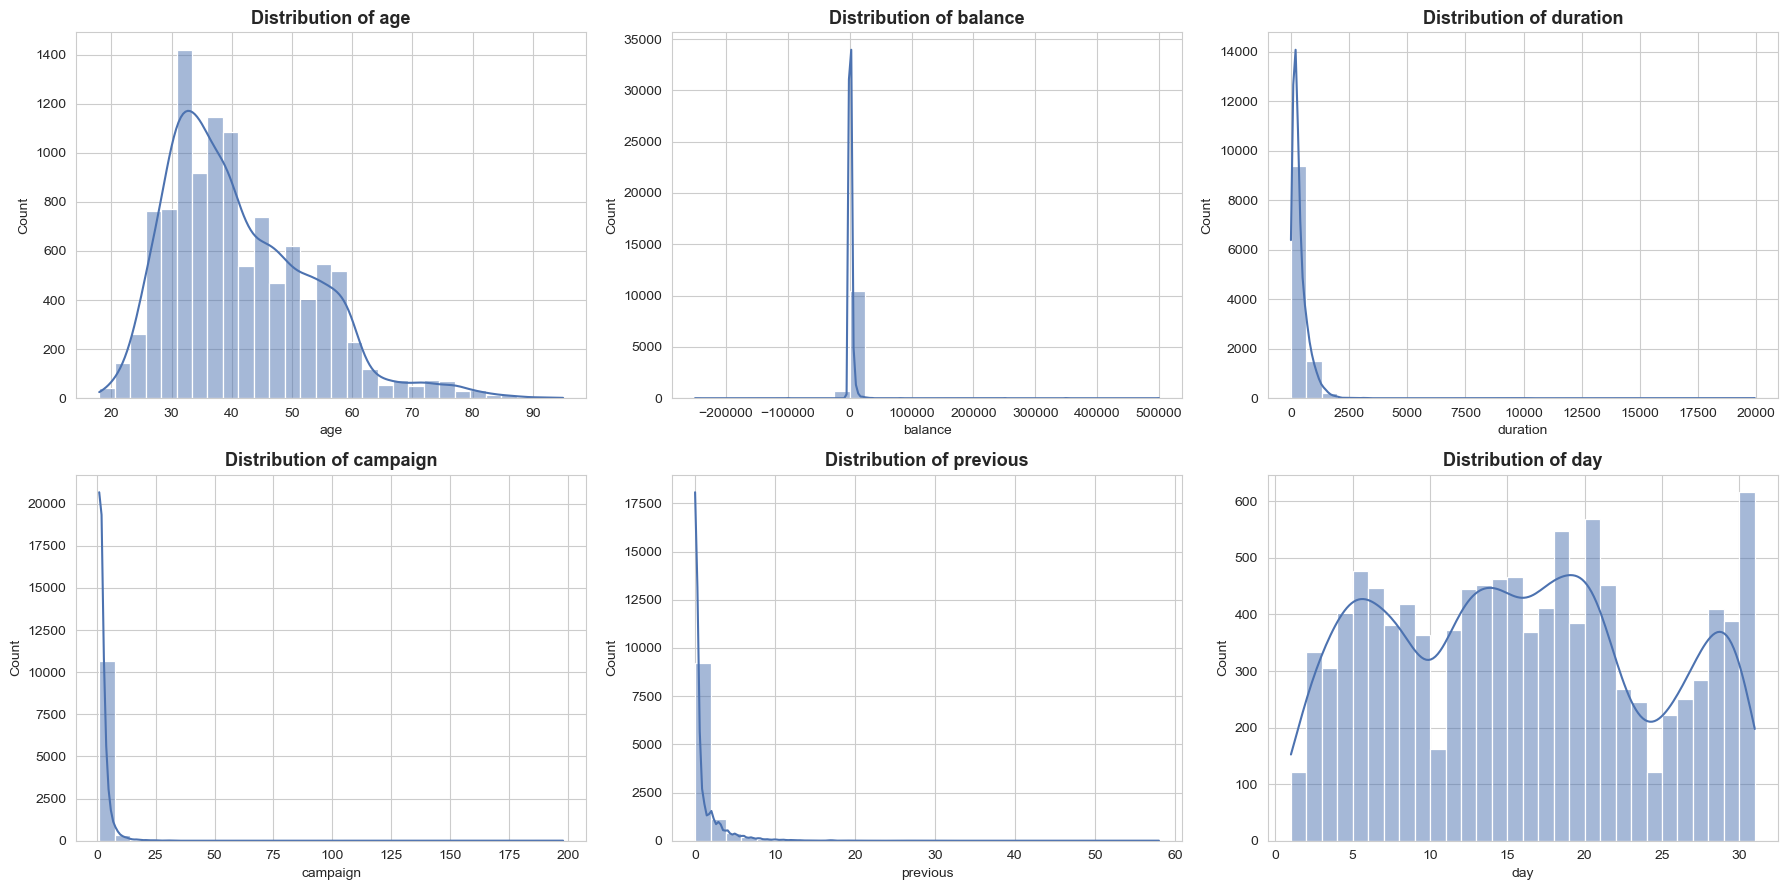

In [41]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, col in zip(axes.flat, ['age','balance','duration','campaign','previous','day']):
    sns.histplot(df[col], kde=True, ax=ax, color='#4C72B0', bins=30)
    ax.set_title(f'Distribution of {col}')
plt.tight_layout()
plt.show()


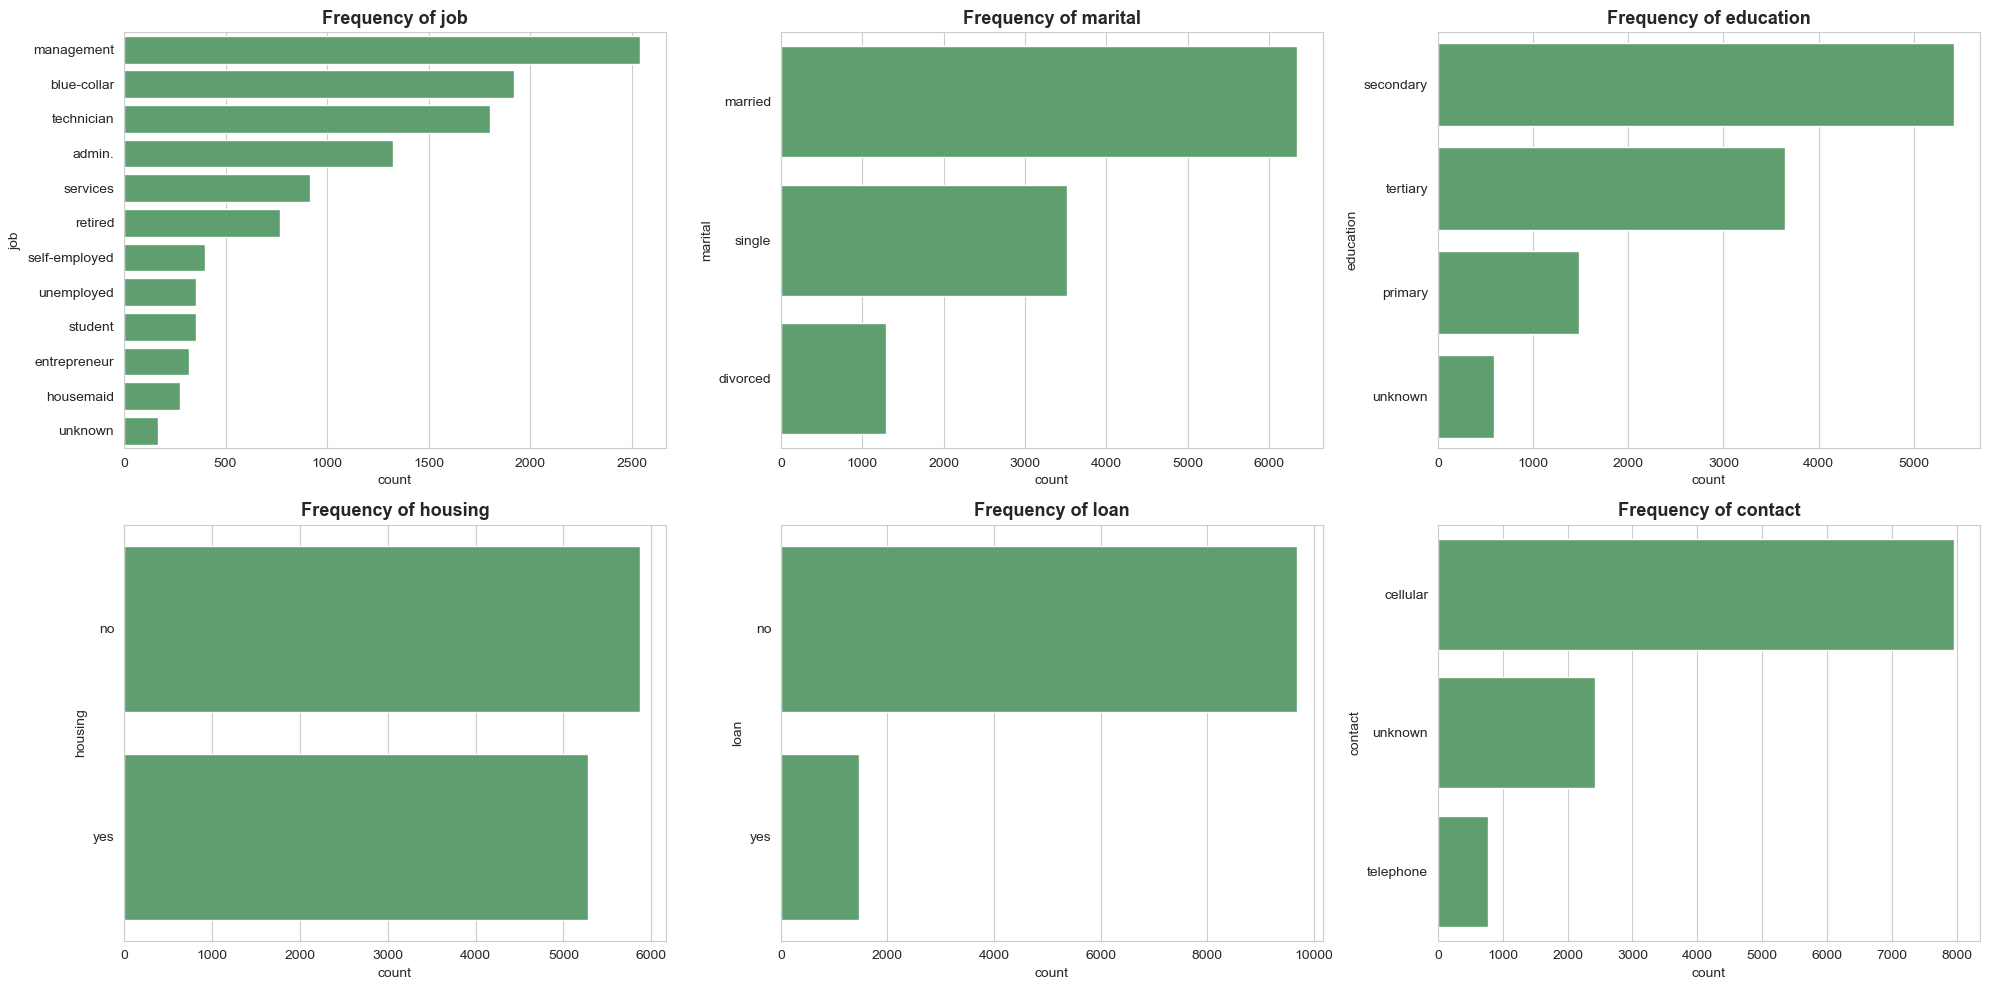

In [42]:
fig, axes = plt.subplots(2, 3, figsize=(20, 10))
cat_plot_cols = ['job','marital','education','housing','loan','contact']
for ax, col in zip(axes.flat, cat_plot_cols):
    order = df[col].value_counts().index
    sns.countplot(y=col, data=df, order=order, ax=ax, color='#55A868')
    ax.set_title(f'Frequency of {col}')
plt.tight_layout()
plt.show()


## 3. Bivariate Analysis

C:\Users\saket\AppData\Local\Temp\ipykernel_23824\3594435324.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='deposit', y=col, data=df, order=['no','yes'], ax=ax, palette=['#C44E52','#55A868'])
C:\Users\saket\AppData\Local\Temp\ipykernel_23824\3594435324.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='deposit', y=col, data=df, order=['no','yes'], ax=ax, palette=['#C44E52','#55A868'])
C:\Users\saket\AppData\Local\Temp\ipykernel_23824\3594435324.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='deposit', y=col, data=df, order

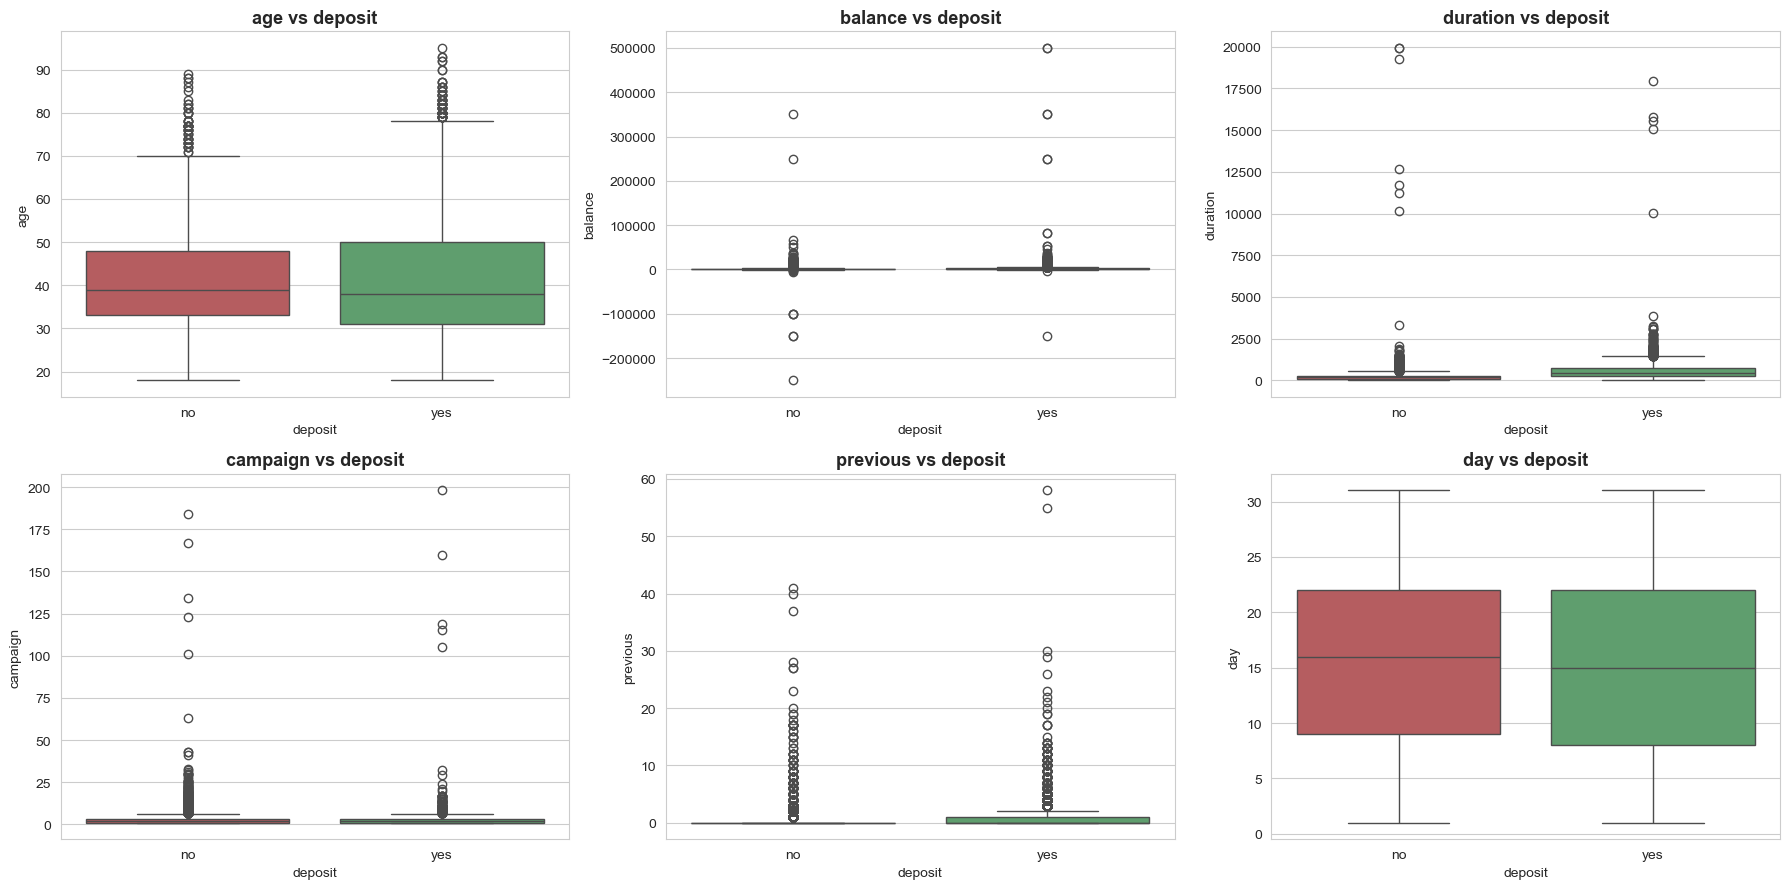

In [43]:
# Numerical feature vs target (deposit)
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, col in zip(axes.flat, ['age','balance','duration','campaign','previous','day']):
    sns.boxplot(x='deposit', y=col, data=df, order=['no','yes'], ax=ax, palette=['#C44E52','#55A868'])
    ax.set_title(f'{col} vs deposit')
plt.tight_layout()
plt.show()


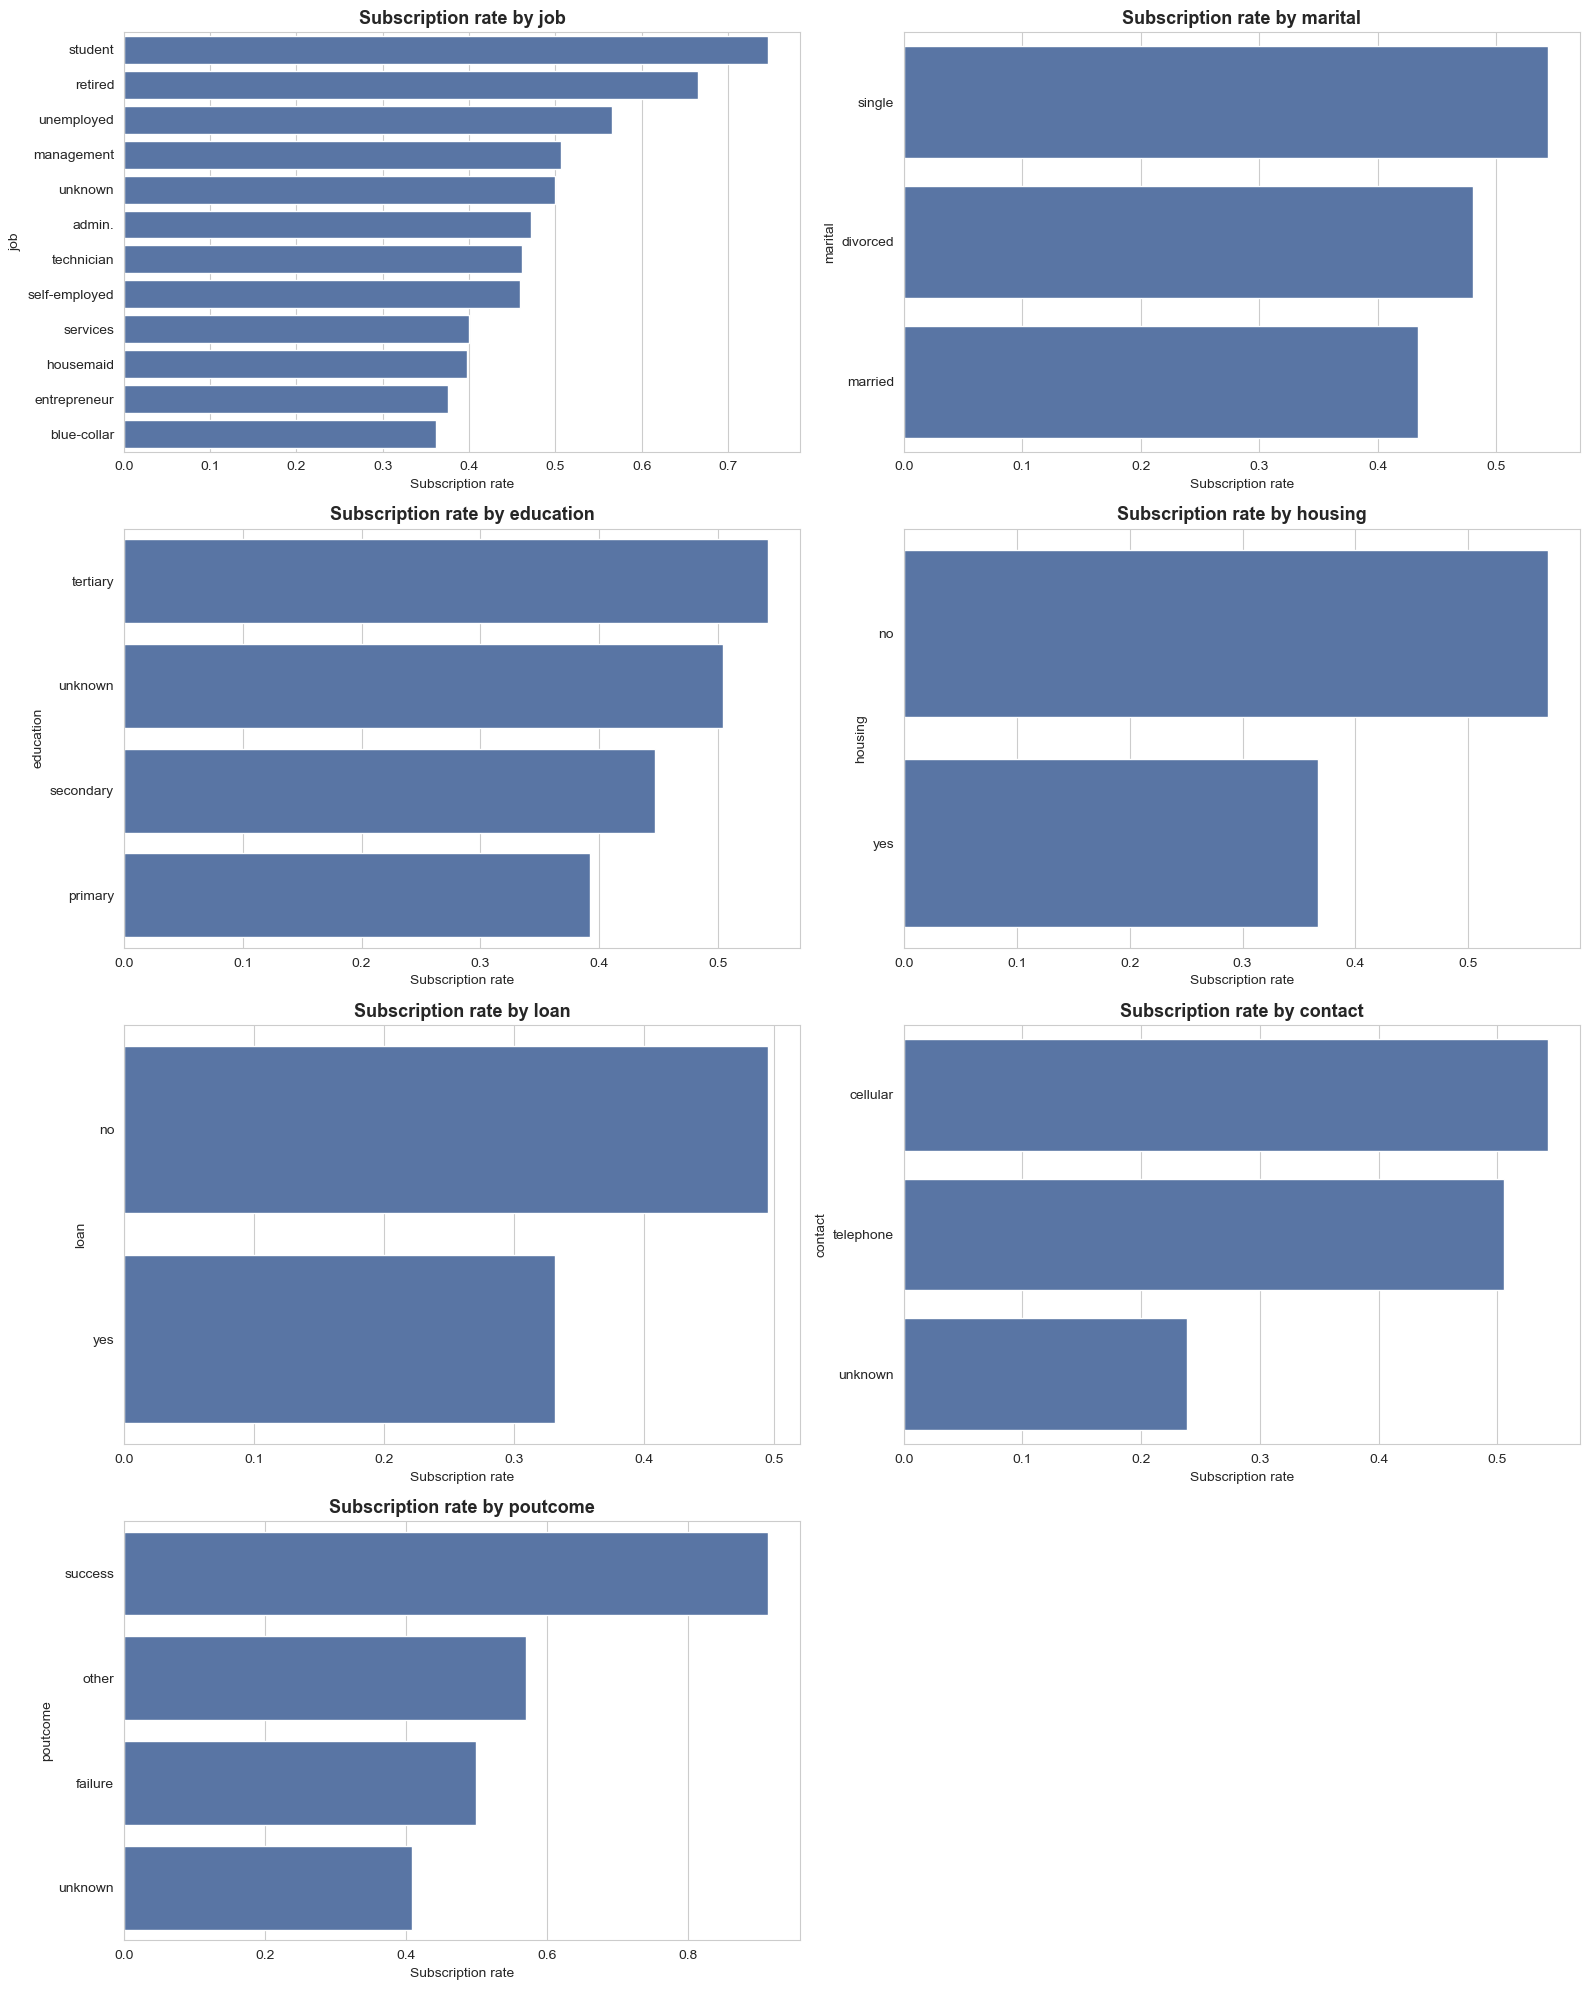

In [46]:
cat_vs_target_cols = ['job','marital','education','housing','loan','contact','poutcome']
fig, axes = plt.subplots(4, 2, figsize=(16, 20))
for ax, col in zip(axes.flat, cat_vs_target_cols):
    rate = df.groupby(col)['deposit'].apply(lambda s: (s=='yes').mean()).sort_values(ascending=False)
    sns.barplot(x=rate.values, y=rate.index, ax=ax, color='#4C72B0')
    ax.set_title(f'Subscription rate by {col}')
    ax.set_xlabel('Subscription rate')
axes.flat[-1].axis('off')
plt.tight_layout()
plt.show()


## 4. Multivariate Analysis

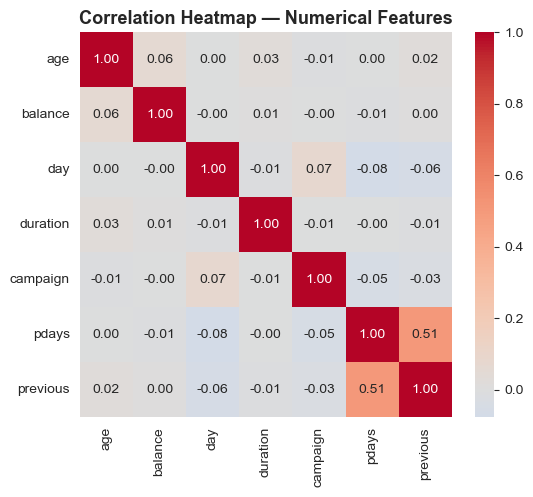

In [47]:
plt.figure(figsize=(6,5))
sns.heatmap(df[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Heatmap — Numerical Features')
plt.show()


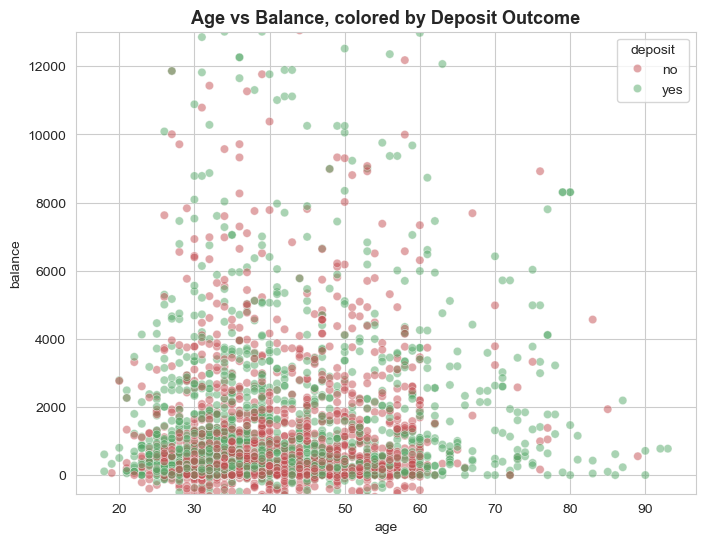

In [48]:
# Age x Balance x Deposit
plt.figure(figsize=(8,6))
sample = df.sample(min(3000, len(df)), random_state=42)
sns.scatterplot(data=sample, x='age', y='balance', hue='deposit', alpha=0.5,
                 palette={'no':'#C44E52','yes':'#55A868'})
plt.ylim(sample['balance'].quantile(0.01), sample['balance'].quantile(0.99))
plt.title('Age vs Balance, colored by Deposit Outcome')
plt.show()


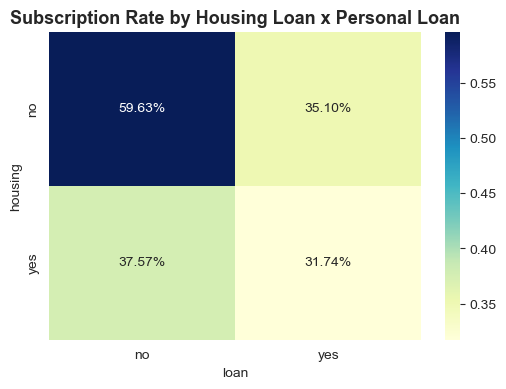

In [50]:
# Housing loan x Personal loan x Deposit (3-way pattern)
combo = df.groupby(['housing','loan'])['deposit'].apply(lambda s: (s=='yes').mean()).unstack()
plt.figure(figsize=(6,4))
sns.heatmap(combo, annot=True, fmt='.2%', cmap='YlGnBu')
plt.title('Subscription Rate by Housing Loan x Personal Loan')
plt.show()


## 5. Group-Based Analysis

In [51]:
grouped = df.groupby('job').agg(
    avg_balance=('balance','mean'),
    median_balance=('balance','median'),
    avg_duration=('duration','mean'),
    avg_campaign=('campaign','mean'),
    subscription_rate=('deposit', lambda s: (s=='yes').mean()),
    n_customers=('deposit','size')
).sort_values('subscription_rate', ascending=False).round(2)
grouped


,avg_balance,median_balance,avg_duration,avg_campaign,subscription_rate,n_customers
job,,,,,,
student,1495.39,505.0,329.58,2.15,0.75,355
retired,3857.36,1107.0,449.06,2.13,0.66,770
unemployed,1306.65,622.0,463.64,2.13,0.57,357
management,1823.50,617.0,382.92,2.71,0.51,2540
unknown,1583.12,578.0,328.89,2.48,0.50,170
admin.,1202.20,479.0,355.23,2.47,0.47,1324
technician,1876.57,549.0,376.20,2.64,0.46,1803
self-employed,1855.17,574.0,396.82,3.19,0.46,401
services,969.17,418.0,395.49,2.78,0.40,916


In [52]:
age_seg = pd.cut(df['age'], bins=[17,25,35,45,55,65,100],
                  labels=['18-25','26-35','36-45','46-55','56-65','66+'])
seg_summary = df.assign(age_group=age_seg).groupby('age_group').agg(
    avg_balance=('balance','mean'),
    subscription_rate=('deposit', lambda s: (s=='yes').mean()),
    n_customers=('deposit','size')
).round(3)
seg_summary


C:\Users\saket\AppData\Local\Temp\ipykernel_23824\2449685178.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  seg_summary = df.assign(age_group=age_seg).groupby('age_group').agg(


,avg_balance,subscription_rate,n_customers
age_group,,,
18-25,1036.885,0.708,445
26-35,1247.966,0.476,3873
36-45,1583.389,0.415,3253
46-55,1812.513,0.416,2120
56-65,2330.605,0.542,1067
66+,5019.332,0.804,392


## 6. Pivot Table Analysis

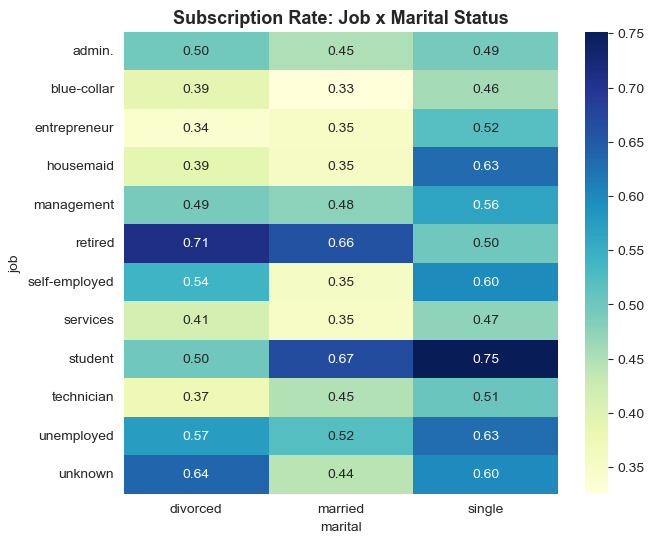

In [53]:
pivot1 = pd.pivot_table(df, index='job', columns='marital', values='deposit',
                         aggfunc=lambda s: (s=='yes').mean())
plt.figure(figsize=(7,6))
sns.heatmap(pivot1, annot=True, fmt='.2f', cmap='YlGnBu')
plt.title('Subscription Rate: Job x Marital Status')
plt.show()


In [54]:
pivot2 = pd.pivot_table(df, index='month', values=['duration','campaign','balance'],
                         aggfunc='mean').reindex(
    ['jan','feb','mar','apr','may','jun','jul','aug','sep','oct','nov','dec'])
pivot2['subscription_rate'] = df.groupby('month')['deposit'].apply(lambda s: (s=='yes').mean()).reindex(pivot2.index)
pivot2.round(2)


,balance,campaign,duration,subscription_rate
month,,,,
jan,1134.63,1.73,380.93,0.41
feb,2661.05,2.16,369.30,0.57
mar,2116.25,2.00,355.93,0.90
apr,1448.68,2.01,420.97,0.62
may,1138.61,2.55,386.17,0.33
jun,1508.85,2.85,383.70,0.45
jul,1376.15,3.39,424.75,0.41
aug,1412.76,3.60,364.43,0.45
sep,1908.20,1.73,351.29,0.84


## 7. Crosstab Analysis

In [55]:
ct1 = pd.crosstab(df['poutcome'], df['deposit'], normalize='index')
print("Previous outcome vs current deposit (row %):")
display(ct1.round(3))

ct2 = pd.crosstab(df['housing'], df['loan'], normalize='index')
print("\nHousing loan vs personal loan (row %):")
display(ct2.round(3))

ct3 = pd.crosstab(df['contact'], df['deposit'], normalize='index')
print("\nContact channel vs deposit (row %):")
display(ct3.round(3))


Previous outcome vs current deposit (row %):


deposit,no,yes
poutcome,,
failure,0.501,0.499
other,0.430,0.570
success,0.087,0.913
unknown,0.592,0.408



Housing loan vs personal loan (row %):


loan,no,yes
housing,,
no,0.894,0.106
yes,0.842,0.158



Contact channel vs deposit (row %):


deposit,no,yes
contact,,
cellular,0.458,0.542
telephone,0.495,0.505
unknown,0.762,0.238


## 8. Advanced Pandas Analysis

In [56]:
# Sorting: top 10 customers by balance who subscribed
top_balance_subscribers = df[df['deposit']=='yes'].sort_values('balance', ascending=False).head(10)
top_balance_subscribers[['age','job','balance','duration','deposit']]


,age,job,balance,duration,deposit
2833,69.0,retired,500000.0,146.0,yes
3125,33.0,entrepreneur,500000.0,563.0,yes
3245,82.0,retired,350000.0,330.0,yes
2769,40.0,technician,350000.0,717.0,yes
52,59.0,retired,250000.0,1125.0,yes
5101,43.0,technician,250000.0,632.0,yes
3039,84.0,retired,81204.0,679.0,yes
3376,84.0,retired,81204.0,390.0,yes
3232,61.0,self-employed,52587.0,255.0,yes
2465,61.0,self-employed,52587.0,290.0,yes


In [57]:
# Filtering: high-value prospects who did NOT subscribe (re-targeting opportunity)
missed_high_value = df[(df['deposit']=='no') & (df['balance'] > df['balance'].quantile(0.9))]
print(f"High-balance customers who did not subscribe: {len(missed_high_value)}")
missed_high_value[['age','job','balance','duration','campaign']].sort_values('balance', ascending=False).head(10)


High-balance customers who did not subscribe: 472


,age,job,balance,duration,campaign
9992,49.0,management,350000.0,99.0,2
6896,51.0,technician,250000.0,187.0,2
8198,52.0,blue-collar,66653.0,109.0,3
10132,43.0,admin.,56831.0,243.0,1
10573,56.0,entrepreneur,51439.0,325.0,1
6985,75.0,retired,37127.0,505.0,1
10756,51.0,entrepreneur,36935.0,41.0,1
8247,53.0,management,34230.0,279.0,1
10915,31.0,technician,31868.0,34.0,6
9475,39.0,technician,29207.0,232.0,2


In [58]:
# Ranking: rank jobs by subscription rate
job_rank = df.groupby('job')['deposit'].apply(lambda s: (s=='yes').mean()).rank(ascending=False).sort_values()
job_rank.round(0).astype(int).rename('rank_by_subscription_rate')

job
student           1
retired           2
unemployed        3
management        4
unknown           5
admin.            6
technician        7
self-employed     8
services          9
housemaid        10
entrepreneur     11
blue-collar      12
Name: rank_by_subscription_rate, dtype: int64

## 9. Correlation & Relationship Analysis

In [59]:
corr_matrix = df[num_cols].corr()
corr_pairs = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)).stack().sort_values(key=abs, ascending=False)
corr_pairs


pdays     previous    0.507312
day       pdays      -0.077209
          campaign    0.070181
age       balance     0.059570
day       previous   -0.058655
campaign  pdays      -0.051176
age       duration    0.031105
campaign  previous   -0.027423
age       previous    0.020299
day       duration   -0.010343
duration  previous   -0.009582
balance   duration    0.008312
age       campaign   -0.006758
balance   pdays      -0.006051
duration  campaign   -0.005275
balance   previous    0.004773
          campaign   -0.004266
duration  pdays      -0.003562
balance   day        -0.002458
age       pdays       0.002368
          day         0.000190
dtype: float64

## 10. Campaign Performance Analysis

C:\Users\saket\AppData\Local\Temp\ipykernel_23824\4044838026.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  dur_summary = df.assign(duration_bucket=dur_bins).groupby('duration_bucket')['deposit'].apply(


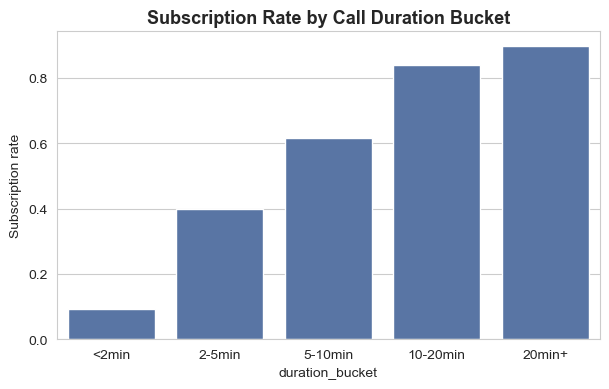

In [60]:
dur_bins = pd.cut(df['duration'], bins=[0,120,300,600,1200,df['duration'].max()],
                   labels=['<2min','2-5min','5-10min','10-20min','20min+'])
dur_summary = df.assign(duration_bucket=dur_bins).groupby('duration_bucket')['deposit'].apply(
    lambda s: (s=='yes').mean())
plt.figure(figsize=(7,4))
sns.barplot(x=dur_summary.index, y=dur_summary.values, color='#4C72B0')
plt.title('Subscription Rate by Call Duration Bucket')
plt.ylabel('Subscription rate')
plt.show()


C:\Users\saket\AppData\Local\Temp\ipykernel_23824\1793030186.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  camp_summary = df.assign(campaign_bucket=camp_bins).groupby('campaign_bucket')['deposit'].apply(


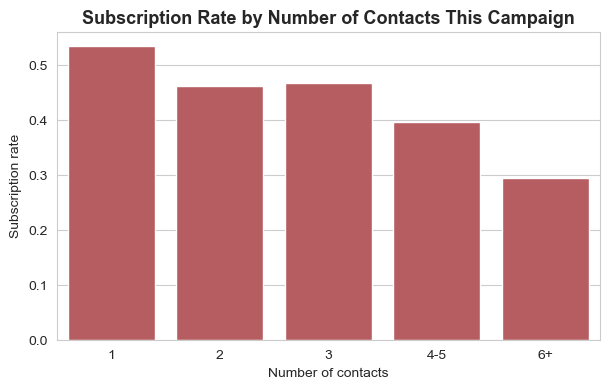

In [61]:
camp_bins = pd.cut(df['campaign'], bins=[0,1,2,3,5,df['campaign'].max()],
                    labels=['1','2','3','4-5','6+'])
camp_summary = df.assign(campaign_bucket=camp_bins).groupby('campaign_bucket')['deposit'].apply(
    lambda s: (s=='yes').mean())
plt.figure(figsize=(7,4))
sns.barplot(x=camp_summary.index, y=camp_summary.values, color='#C44E52')
plt.title('Subscription Rate by Number of Contacts This Campaign')
plt.ylabel('Subscription rate')
plt.xlabel('Number of contacts')
plt.show()


## 11. Customer Segment Analysis

In [62]:
segment_summary = df.groupby(['job','housing']).agg(
    subscription_rate=('deposit', lambda s: (s=='yes').mean()),
    n=('deposit','size')
).query('n >= 50').sort_values('subscription_rate', ascending=False).round(3)
segment_summary.head(15)


,,subscription_rate,n
job,housing,,
student,no,0.800,305
retired,no,0.710,648
unemployed,no,0.661,245
management,no,0.581,1478
admin.,no,0.577,591
unknown,no,0.564,117
technician,no,0.531,938
self-employed,no,0.515,229
services,no,0.513,353


## 12–13. Data Visualization & Visual Storytelling Summary

C:\Users\saket\AppData\Local\Temp\ipykernel_23824\3290708610.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='deposit', y='duration', data=df, order=['no','yes'],
C:\Users\saket\AppData\Local\Temp\ipykernel_23824\3290708610.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='deposit', y='balance', data=df[df['balance'].between(


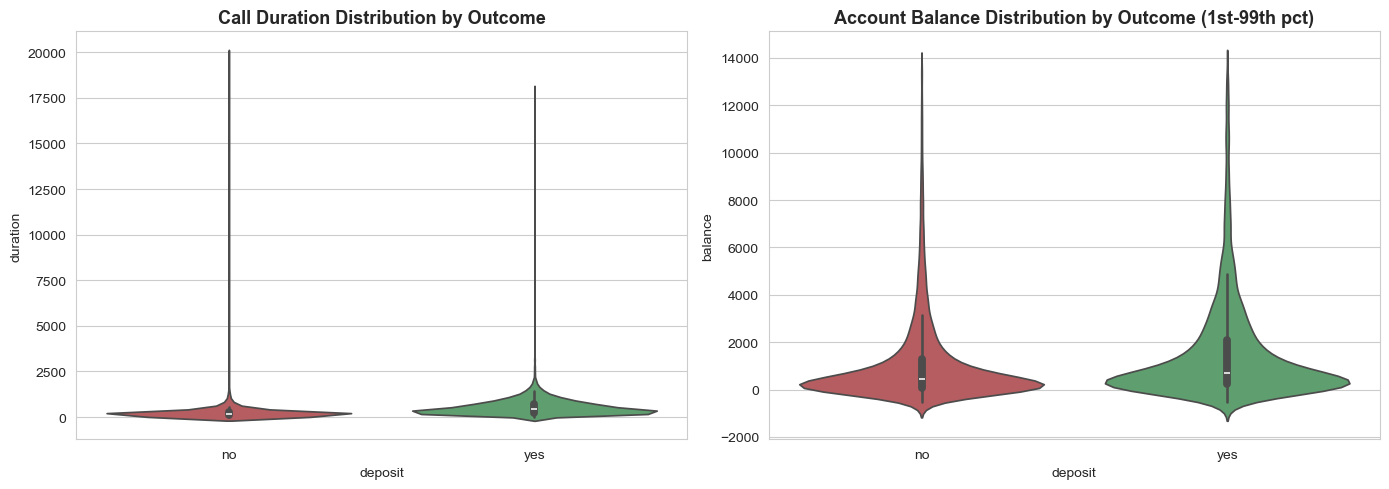

In [63]:
fig, axes = plt.subplots(1, 2, figsize=(14,5))
sns.violinplot(x='deposit', y='duration', data=df, order=['no','yes'],
               palette=['#C44E52','#55A868'], ax=axes[0])
axes[0].set_title('Call Duration Distribution by Outcome')

sns.violinplot(x='deposit', y='balance', data=df[df['balance'].between(
    df['balance'].quantile(.01), df['balance'].quantile(.99))],
               order=['no','yes'], palette=['#C44E52','#55A868'], ax=axes[1])
axes[1].set_title('Account Balance Distribution by Outcome (1st-99th pct)')
plt.tight_layout()
plt.show()


---
# 📈 SPRINT 3 — Advanced Statistics, Hypothesis Testing & Feature Engineering

**Sprint Goal:** Statistically validate key findings from Sprint 2 and engineer features that add
analytical value.

In [64]:
df = pd.read_csv('bank_marketing_cleaned.csv')
df.shape

(11150, 17)

## 1. Statistical Analysis

In [65]:
stats_table = pd.DataFrame({
    'mean': df[num_cols].mean(),
    'median': df[num_cols].median(),
    'std': df[num_cols].std(),
    'variance': df[num_cols].var(),
    'IQR': df[num_cols].quantile(.75) - df[num_cols].quantile(.25),
    'skewness': df[num_cols].skew(),
    'kurtosis': df[num_cols].kurt(),
}).round(2)
stats_table


,mean,median,std,variance,IQR,skewness,kurtosis
age,41.19,39.0,11.83,1.399800e+02,17.00,0.87,0.67
balance,1680.93,551.0,10900.17,1.188137e+08,1568.00,27.27,1172.89
day,15.66,15.0,8.42,7.088000e+01,14.00,0.11,-1.06
duration,386.37,255.0,600.88,3.610574e+05,353.00,18.47,506.78
campaign,2.63,2.0,5.04,2.542000e+01,2.00,22.41,687.80
pdays,51.28,-1.0,108.66,1.180679e+04,20.25,2.45,6.85
previous,0.83,0.0,2.29,5.260000e+00,1.00,7.34,106.23


In [66]:
cov_matrix = df[num_cols].cov()
cov_matrix.round(1)


,age,balance,day,duration,campaign,pdays,previous
age,140.0,7682.3,0.0,221.1,-0.4,3.0,0.6
balance,7682.3,118813696.0,-225.5,54438.7,-234.4,-7166.4,119.3
day,0.0,-225.5,70.9,-52.3,3.0,-70.6,-1.1
duration,221.1,54438.7,-52.3,361057.4,-16.0,-232.6,-13.2
campaign,-0.4,-234.4,3.0,-16.0,25.4,-28.0,-0.3
pdays,3.0,-7166.4,-70.6,-232.6,-28.0,11806.8,126.4
previous,0.6,119.3,-1.1,-13.2,-0.3,126.4,5.3


## 2. Hypothesis Testing

In [67]:
dur_yes = df.loc[df['deposit']=='yes', 'duration']
dur_no  = df.loc[df['deposit']=='no', 'duration']

# Welch's t-test (does not assume equal variances) -- more robust for skewed, unequal-size groups
t_stat, p_val = stats.ttest_ind(dur_yes, dur_no, equal_var=False)

print(f"Mean duration (yes): {dur_yes.mean():.1f}s | Mean duration (no): {dur_no.mean():.1f}s")
print(f"T-statistic: {t_stat:.3f}")
print(f"P-value: {p_val:.4g}")
alpha = 0.05
decision = "Reject H0" if p_val < alpha else "Fail to reject H0"
print(f"Decision at alpha={alpha}: {decision}")


Mean duration (yes): 547.7s | Mean duration (no): 241.1s
T-statistic: 27.751
P-value: 7.68e-164
Decision at alpha=0.05: Reject H0


## Test 2

In [69]:
ct_housing = pd.crosstab(df['housing'], df['deposit'])
chi2, p_val, dof, expected = stats.chi2_contingency(ct_housing)
print(ct_housing)
print(f"\nChi2 statistic: {chi2:.2f}, dof: {dof}, p-value: {p_val:.4g}")
decision = "Reject H0" if p_val < alpha else "Fail to reject H0"
print(f"Decision at alpha={alpha}: {decision}")


deposit    no   yes
housing            
no       2524  3349
yes      3343  1934

Chi2 statistic: 461.97, dof: 1, p-value: 1.792e-102
Decision at alpha=0.05: Reject H0


## Test 3

In [70]:
ct_edu = pd.crosstab(df['education'], df['deposit'])
chi2, p_val, dof, expected = stats.chi2_contingency(ct_edu)
print(ct_edu)
print(f"\nChi2 statistic: {chi2:.2f}, dof: {dof}, p-value: {p_val:.4g}")
decision = "Reject H0" if p_val < alpha else "Fail to reject H0"
print(f"Decision at alpha={alpha}: {decision}")


deposit      no   yes
education            
primary     904   583
secondary  3000  2425
tertiary   1670  1977
unknown     293   298

Chi2 statistic: 125.88, dof: 3, p-value: 4.173e-27
Decision at alpha=0.05: Reject H0


## Test 4

In [71]:
job_groups = [group['balance'].values for _, group in df.groupby('job')]
f_stat, p_val = stats.f_oneway(*job_groups)
print(f"F-statistic: {f_stat:.3f}")
print(f"P-value: {p_val:.4g}")
decision = "Reject H0" if p_val < alpha else "Fail to reject H0"
print(f"Decision at alpha={alpha}: {decision}")

print("\nMean balance by job:")
print(df.groupby('job')['balance'].mean().sort_values(ascending=False).round(0))


F-statistic: 4.860
P-value: 1.546e-07
Decision at alpha=0.05: Reject H0

Mean balance by job:
job
retired          3857.0
entrepreneur     3189.0
technician       1877.0
self-employed    1855.0
management       1824.0
unknown          1583.0
student          1495.0
housemaid        1346.0
unemployed       1307.0
admin.           1202.0
blue-collar       976.0
services          969.0
Name: balance, dtype: float64


## 3. Confidence Interval Analysis

In [72]:
def proportion_ci(successes, n, confidence=0.95):
    p_hat = successes / n
    z = stats.norm.ppf(1 - (1-confidence)/2)
    se = np.sqrt(p_hat*(1-p_hat)/n)
    return p_hat, (p_hat - z*se, p_hat + z*se)

overall_successes = (df['deposit']=='yes').sum()
p_hat, (lo, hi) = proportion_ci(overall_successes, len(df))
print(f"Overall subscription rate: {p_hat:.3%}")
print(f"95% Confidence Interval: [{lo:.3%}, {hi:.3%}]")


Overall subscription rate: 47.381%
95% Confidence Interval: [46.454%, 48.308%]


In [73]:
# CI for mean balance (t-distribution based, appropriate given large-but-not-infinite sample)
mean_bal = df['balance'].mean()
sem_bal = stats.sem(df['balance'])
ci_bal = stats.t.interval(0.95, len(df)-1, loc=mean_bal, scale=sem_bal)
print(f"Mean balance: {mean_bal:,.2f}")
print(f"95% CI for mean balance: [{ci_bal[0]:,.2f}, {ci_bal[1]:,.2f}]")

# CI for the difference in subscription rate: previously-successful vs never-contacted customers
succ_mask = df['poutcome']=='success'
never_mask = df['pdays']==-1

p1, ci1 = proportion_ci((df.loc[succ_mask,'deposit']=='yes').sum(), succ_mask.sum())
p2, ci2 = proportion_ci((df.loc[never_mask,'deposit']=='yes').sum(), never_mask.sum())
print(f"\nSubscription rate | previous outcome = success: {p1:.2%}  95% CI [{ci1[0]:.2%}, {ci1[1]:.2%}]")
print(f"Subscription rate | never contacted before:        {p2:.2%}  95% CI [{ci2[0]:.2%}, {ci2[1]:.2%}]")


Mean balance: 1,680.93
95% CI for mean balance: [1,478.59, 1,883.28]

Subscription rate | previous outcome = success: 91.35%  95% CI [89.65%, 93.04%]
Subscription rate | never contacted before:        40.64%  95% CI [39.59%, 41.70%]


## 4. Feature Engineering

In [74]:
df_feat = df.copy()

# 1) was_previously_contacted -- makes the pdays=-1 sentinel explicit and usable
df_feat['was_previously_contacted'] = (df_feat['pdays'] != -1).astype(int)

# 2) age_group -- life-stage segmentation identified as meaningful in Sprint 2
df_feat['age_group'] = pd.cut(df_feat['age'], bins=[17,25,35,45,55,65,100],
                               labels=['18-25','26-35','36-45','46-55','56-65','66+'])

# 3) balance_category -- simple, business-readable wealth tiers
df_feat['balance_category'] = pd.cut(
    df_feat['balance'],
    bins=[-np.inf, 0, 1000, 5000, np.inf],
    labels=['negative/overdrawn','low (0-1000)','medium (1000-5000)','high (5000+)']
)

# 4) duration_minutes -- more interpretable business unit than raw seconds
df_feat['duration_minutes'] = (df_feat['duration'] / 60).round(2)

# 5) has_any_loan -- combined loan-burden flag (housing OR personal loan)
df_feat['has_any_loan'] = ((df_feat['housing']=='yes') | (df_feat['loan']=='yes')).astype(int)

# 6) contact_intensity -- campaign-fatigue tiering, using the diminishing-returns pattern from Sprint 2
df_feat['contact_intensity'] = pd.cut(df_feat['campaign'], bins=[0,1,2,3,5,df_feat['campaign'].max()],
                                       labels=['1_contact','2_contacts','3_contacts','4-5_contacts','6+_contacts'])

# 7) prior_campaign_success -- binary flag isolating the single strongest predictor found in Sprint 2/3
df_feat['prior_campaign_success'] = (df_feat['poutcome']=='success').astype(int)

# 8) is_engaged_call -- binary flag for calls in the higher-converting duration bucket (>=5 min)
df_feat['is_engaged_call'] = (df_feat['duration'] >= 300).astype(int)

df_feat[['pdays','was_previously_contacted','age','age_group','balance','balance_category',
         'duration','duration_minutes','housing','loan','has_any_loan',
         'campaign','contact_intensity','poutcome','prior_campaign_success',
         'is_engaged_call']].head(8)


,pdays,was_previously_contacted,age,age_group,balance,balance_category,duration,duration_minutes,housing,loan,has_any_loan,campaign,contact_intensity,poutcome,prior_campaign_success,is_engaged_call
0,-1,0,59.0,56-65,2343.0,medium (1000-5000),1042.0,17.37,yes,no,1,1,1_contact,unknown,0,1
1,-1,0,56.0,56-65,45.0,low (0-1000),1467.0,24.45,no,no,0,1,1_contact,unknown,0,1
2,-1,0,41.0,36-45,1270.0,medium (1000-5000),1389.0,23.15,yes,no,1,1,1_contact,unknown,0,1
3,-1,0,55.0,46-55,2476.0,medium (1000-5000),579.0,9.65,yes,no,1,1,1_contact,unknown,0,1
4,-1,0,54.0,46-55,184.0,low (0-1000),673.0,11.22,no,no,0,2,2_contacts,unknown,0,1
5,-1,0,42.0,36-45,0.0,negative/overdrawn,562.0,9.37,yes,yes,1,2,2_contacts,unknown,0,1
6,-1,0,56.0,56-65,830.0,low (0-1000),1201.0,20.02,yes,yes,1,1,1_contact,unknown,0,1
7,-1,0,60.0,56-65,545.0,low (0-1000),1030.0,17.17,yes,no,1,1,1_contact,unknown,0,1


## 5. Feature Evaluation — Before vs After

In [75]:
print("BEFORE feature engineering — raw pdays view:")
print(df_feat['pdays'].describe())
print("\n(Misleading: averaging -1 with real day-counts produces a meaningless 'mean days'.)")

print("\nAFTER feature engineering — was_previously_contacted view:")
print(df_feat.groupby('was_previously_contacted')['deposit'].apply(lambda s: (s=='yes').mean()).round(3))


BEFORE feature engineering — raw pdays view:
count    11150.000000
mean        51.279372
std        108.659050
min         -1.000000
25%         -1.000000
50%         -1.000000
75%         19.250000
max        854.000000
Name: pdays, dtype: float64

(Misleading: averaging -1 with real day-counts produces a meaningless 'mean days'.)

AFTER feature engineering — was_previously_contacted view:
was_previously_contacted
0    0.406
1    0.671
Name: deposit, dtype: float64


C:\Users\saket\AppData\Local\Temp\ipykernel_23824\3636141440.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  age_after = df_feat.groupby('age_group')['deposit'].apply(lambda s: (s=='yes').mean())


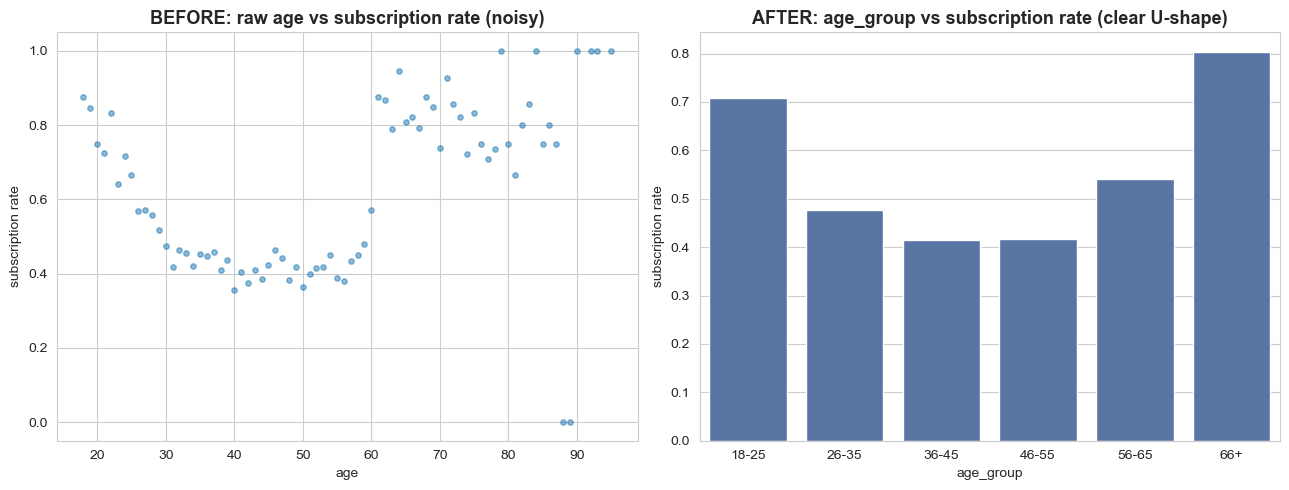

In [76]:
fig, axes = plt.subplots(1, 2, figsize=(13,5))

age_before = df_feat.groupby('age')['deposit'].apply(lambda s: (s=='yes').mean())
axes[0].scatter(age_before.index, age_before.values, alpha=0.5, s=15)
axes[0].set_title('BEFORE: raw age vs subscription rate (noisy)')
axes[0].set_xlabel('age'); axes[0].set_ylabel('subscription rate')

age_after = df_feat.groupby('age_group')['deposit'].apply(lambda s: (s=='yes').mean())
sns.barplot(x=age_after.index, y=age_after.values, color='#4C72B0', ax=axes[1])
axes[1].set_title('AFTER: age_group vs subscription rate (clear U-shape)')
axes[1].set_ylabel('subscription rate')
plt.tight_layout()
plt.show()


In [77]:
print("Subscription rate by engineered contact_intensity (clear monotonic trend):")
print(df_feat.groupby('contact_intensity')['deposit'].apply(lambda s: (s=='yes').mean()).round(3))

print("\nSubscription rate by has_any_loan flag (0=no loans, 1=at least one loan):")
print(df_feat.groupby('has_any_loan')['deposit'].apply(lambda s: (s=='yes').mean()).round(3))

print("\nSubscription rate by prior_campaign_success flag:")
print(df_feat.groupby('prior_campaign_success')['deposit'].apply(lambda s: (s=='yes').mean()).round(3))


Subscription rate by engineered contact_intensity (clear monotonic trend):
contact_intensity
1_contact       0.534
2_contacts      0.462
3_contacts      0.468
4-5_contacts    0.397
6+_contacts     0.295
Name: deposit, dtype: float64

Subscription rate by has_any_loan flag (0=no loans, 1=at least one loan):
has_any_loan
0    0.596
1    0.365
Name: deposit, dtype: float64

Subscription rate by prior_campaign_success flag:
prior_campaign_success
0    0.427
1    0.913
Name: deposit, dtype: float64


C:\Users\saket\AppData\Local\Temp\ipykernel_23824\1930502018.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(df_feat.groupby('contact_intensity')['deposit'].apply(lambda s: (s=='yes').mean()).round(3))


In [78]:
df_feat.to_csv('bank_marketing_feature_engineered.csv', index=False)
print("Saved -> bank_marketing_feature_engineered.csv")
df_feat.shape


Saved -> bank_marketing_feature_engineered.csv


(11150, 25)